# Exploring Convolutions and Max Pooling

## Objective
Apply a convolution filter to a grayscale image and implement max pooling to see how they highlight image features and reduce image size.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.datasets import ascent

c:\Users\lekal\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and Display the Image

The SciPy `ascent` sample is a 512 × 512 grayscale image. It is stored as a NumPy array.

Image dimension: (512,512) 


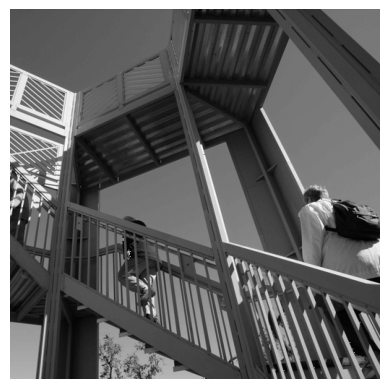

In [2]:
# Load image
ascent_image = ascent().astype(np.float32)

# Visualize image
plt.imshow(ascent_image)
plt.axis('off')
plt.gray()

# copy image as numpy array
image_transformed=np.copy(ascent_image)

# get image dimension
x_size=image_transformed.shape[0]
y_size=image_transformed.shape[1]
print(f"Image dimension: ({x_size},{y_size}) ")

## 2. Define a Convolution Filter

A 3 × 3 filter moves across the image. At each position, the image pixels are multiplied by the matching filter values and added together.

The filter used here highlights edges. Other filters can respond to different patterns, such as horizontal or vertical lines.

In [3]:
# filter
filter = [[0, 1, 0], [1, -4, 1], [0, 1, 0]]

# filter = [ [-1, -2, -1], [0, 0, 0], [1, 2, 1]]
# filter = [ [-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
weight  = 1

## 3. Apply the Convolution

Convolve filter over the image, leaving a 1 pixel margin, and multiplying each of the neighbors of the current pixel by the value defined in the filter 

You'll then multiply the result by the weight, and then ensure the result is in the range 0-255.

Finally you'll load the new value into the transformed image.


In [4]:
for x in range(1, x_size-1):
    for y in range(1, y_size-1):
        convolution = 0.0
        convolution = convolution + (ascent_image[x-1, y-1] * filter[0][0])
        convolution = convolution + (ascent_image[x-1, y] * filter[0][1])  
        convolution = convolution + (ascent_image[x-1, y+1] * filter[0][2])     
        convolution = convolution + (ascent_image[x, y-1] * filter[1][0])    
        convolution = convolution + (ascent_image[x, y] * filter[1][1])    
        convolution = convolution + (ascent_image[x, y+1] * filter[1][2])    
        convolution = convolution + (ascent_image[x+1, y-1] * filter[2][0])    
        convolution = convolution + (ascent_image[x+1, y] * filter[2][1])    
        convolution = convolution + (ascent_image[x+1, y+1] * filter[2][2])    
      
        # Multiply by weight
        convolution = convolution * weight   
      
        # Check the boundaries of the pixel values
        if(convolution < 0):
            convolution = 0
        if(convolution > 255):
            convolution = 255

        # Load into the transformed image
        image_transformed[x, y] = convolution

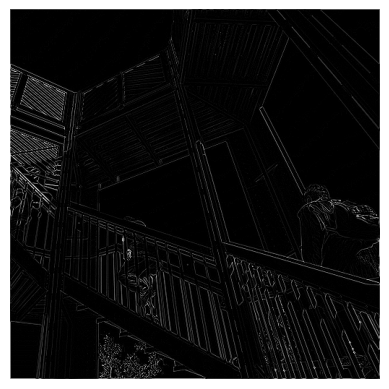

In [5]:
# Visualize the image
plt.imshow(image_transformed)
plt.axis('off')
plt.gray()

## 4. Effect of Max Pooling

 The idea here is to iterate over the image, and look at the pixel and it's immediate neighbors to the right, beneath, and right-beneath. It will take the largest of them and load it into the new image. Thus, the new image will be 1/4 the size of the old -- with the dimensions on X and Y being halved by this process. The features get maintained despite this compression!

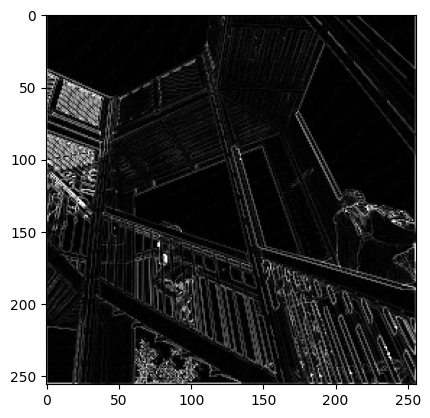

In [6]:
# Assign dimensions half the size of the original image
new_x = int(x_size / 2)
new_y = int(y_size / 2)

# Create blank image with reduced dimensions
newImage = np.zeros((new_x, new_y))

# Iterate over the image
for x in range(0, x_size, 2):
    for y in range(0, y_size, 2):
    
        # Store all the pixel values in the (2,2) pool
        pixels = []
        pixels.append(image_transformed[x, y])
        pixels.append(image_transformed[x+1, y])
        pixels.append(image_transformed[x, y+1])
        pixels.append(image_transformed[x+1, y+1])

        # Get only the largest value and assign to the reduced image
        newImage[int(x / 2), int(y / 2)] = max(pixels)

# Plot the image. Note the size of the axes -- it is now half of the image loaded earlier
plt.gray()
plt.grid(False)
plt.imshow(newImage)
plt.show()